# Design study: finned tubes or a packed bed?

PyTES models share their outputs, parameters, experiments and energy reference across
families (DESIGN D4), so different designs compare like for like. This notebook uses that
to answer a practical question:

> A heat battery for domestic hot water should store about 2 kWh between 10 °C and 70 °C
> and deliver 5 kW until its outlet falls below 40 °C. Should it be a finned-tube unit or a
> packed bed of PCM capsules?

The point is the workflow, not a verdict: with other materials, sizes or heat transfer
coefficients the answer changes.

In [1]:
import pytes
from pytes import plotting
from pytes.experiments import Experiment, run_experiment
from pytes.experiments import step as s

T_cold, T_hot = 273.15 + 10, 273.15 + 70

## Same PCM, same storable energy

The finned-tube unit is the default sharp-front model with 4 tubes. The packed bed takes the
same PCM, fluid and temperatures from it (parameters are layered by prefix, DESIGN D1), and
its cross-section is sized with `energy_between` so that it stores the same energy between
10 °C and 70 °C.

In [2]:
finned = pytes.SharpFrontModel()
finned_values = finned.default_parameter_values
finned_values["Number of tubes"] = 4
capacity = pytes.energy_between(finned, T_cold, T_hot, finned_values)

bed = pytes.PackedBedModel()
bed_values = bed.default_parameter_values
shared = (
    "Reference temperature [K]",
    "Initial temperature [K]",
    "Inlet temperature [K]",
)
for name, value in finned_values.items():
    if name.startswith(("PCM ", "Heat transfer fluid ")) or name in shared:
        bed_values[name] = value
bed_values["Bed cross-sectional area [m2]"] = 1
per_area = pytes.energy_between(bed, T_cold, T_hot, bed_values)
bed_values["Bed cross-sectional area [m2]"] = capacity / per_area

print(f"finned tubes: {capacity / 3.6e6:.2f} kWh")
print(
    f"packed bed: {pytes.energy_between(bed, T_cold, T_hot, bed_values) / 3.6e6:.2f} kWh, "
    f"cross-section {capacity / per_area:.3f} m2"
)

finned tubes: 2.01 kWh
packed bed: 2.01 kWh, cross-section 0.038 m2


## The same test for both

Both start full (uniform at 70 °C) and deliver 5 kW with water at 10 °C, the flow adjusted
to hold the power, until the outlet falls below 40 °C.

finned tubes: 5 kW for 21.6 min, delivering 1.80 kWh (90% of what it stores)


packed bed: 5 kW for 8.4 min, delivering 0.70 kWh (35% of what it stores)


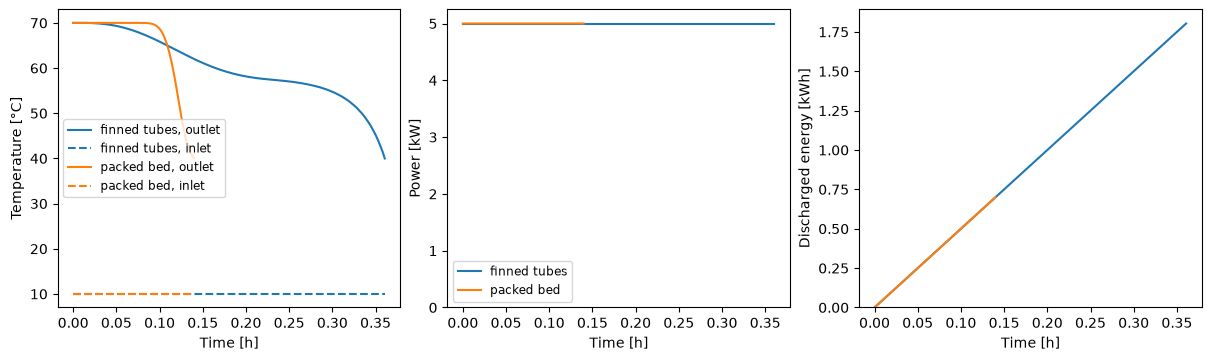

In [3]:
test = Experiment(
    [
        s.ConstantPower(
            5e3,
            inlet_temperature=T_cold,
            termination=[
                s.outlet_temperature_below(273.15 + 40),
                s.mass_flow_rate_above(1.0),
            ],
            period=10,
        )
    ]
)
results = {}
for name, model, values in [
    ("finned tubes", finned, finned_values),
    ("packed bed", bed, bed_values),
]:
    results[name] = run_experiment(model, test, parameter_values=values)
    delivered = results[name]["Discharged energy [J]"].entries[-1]
    minutes = results[name]["Time [min]"].entries[-1]
    print(
        f"{name}: 5 kW for {minutes:.1f} min, delivering {delivered / 3.6e6:.2f} kWh "
        f"({delivered / capacity:.0%} of what it stores)"
    )

fig, axes = plotting.plot_summary(list(results.values()), labels=list(results))

Both store the same energy, but the finned unit delivers most of it before the outlet
cools, while the bed delivers about a third: heat leaves its large paraffin capsules (55 mm
across) slowly, through a low film coefficient and a poorly conducting PCM, so the outlet
cools long before the capsules are spent.

## What would make the bed competitive?

Smaller capsules at the same porosity store the same energy but expose more surface and
conduct over a shorter distance.

In [4]:
for radius in (27.5e-3, 15e-3, 7.5e-3):
    values = bed_values.copy()
    values["Capsule radius [m]"] = radius
    solution = run_experiment(bed, test, parameter_values=values)
    delivered = solution["Discharged energy [J]"].entries[-1]
    print(
        f"capsules of {2e3 * radius:4.0f} mm: 5 kW for "
        f"{solution['Time [min]'].entries[-1]:5.1f} min, {delivered / capacity:.0%} delivered"
    )

capsules of   55 mm: 5 kW for   8.4 min, 35% delivered


capsules of   30 mm: 5 kW for  12.9 min, 54% delivered


capsules of   15 mm: 5 kW for  19.8 min, 82% delivered


The same few lines answer the next question too: a different PCM, a higher film
coefficient, more tubes. Every family exposes the same outputs and runs the same experiments,
so a comparison is a loop over models and parameter values.